# APRAU 2026/27 - Grupo 08
## Parte 2: Regressão Linear Múltipla (`target_regression`)

Ponto 3 do enunciado: ajustar um modelo de regressão linear múltipla com várias *features*, experimentar combinações de variáveis, escolher o grupo com melhor desempenho e avaliá-lo com $R^2$, MAE e RMSE.

O notebook segue os slides de *Linear Regression* e responde às quatro perguntas que os slides colocam a um modelo de regressão:

| Pergunta dos slides | Secção |
|---|---|
| 1. Que preditores são úteis? | 5 |
| 2. São todos úteis, ou só um subconjunto? | 6 |
| 3. Quão bem se ajusta o modelo? | 7 |
| 4. Dados novos valores dos preditores, que resposta prever? | 8 |
| Comparação com a regressão simples (enunciado) | 10 |

Ferramentas (as dos slides): `smf.ols` (*statsmodels*) para coeficientes e p-values, `LinearRegression` (*scikit-learn*) para ajustar e prever, `r2_score` e `mean_squared_error` para avaliar, e `corr()` para ver correlações.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import sklearn.linear_model as skl_lm
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
df = pd.read_csv("dataset_grupo_08.csv")
print(df.shape)

(2000, 35)


---
## 1. Dados e codificação

`target_regression` é a resposta $Y$. A regressão linear só aceita preditores numéricos, por isso as variáveis categóricas são codificadas (a mesma lógica do `task1`):

| Tipo | Variáveis | Codificação |
|---|---|---|
| ordinal | `physical_activity`, `stress_level`, `sugar_consumption` | 1, 2, 3 pela ordem natural |
| binária | `gender`, `family_history`, `low_hdl_cholesterol`, `high_ldl_cholesterol` | 0/1 (`Female` e `Yes` = 1) |
| nominal | `smoking`, `education_level`, `employment_status` | *dummies* 0/1; a primeira categoria fica como **referência** (`Never`, `Primary`, `Unemployed`) |

Ficam fora `target_class` (é o alvo da classificação), `bmi_level` e `age_level` (são `bmi` e `age` em categorias).

In [2]:
target = "target_regression"
data = df.drop(columns=["target_class", "bmi_level", "age_level"])

# ordinais: ordem natural
for col in ["physical_activity", "stress_level", "sugar_consumption"]:
    data[col] = data[col].map({"Low": 1, "Moderate": 2, "Medium": 2, "High": 3})

# binárias: 0/1
data["gender"] = (data["gender"] == "Female").astype(int)
for col in ["family_history", "low_hdl_cholesterol", "high_ldl_cholesterol"]:
    data[col] = (data[col] == "Yes").astype(int)

# nominais: dummies; a primeira categoria de cada lista é a referência
nominal = {
    "smoking": ["Never", "Former", "Current"],
    "education_level": ["Primary", "Secondary", "Tertiary"],
    "employment_status": ["Unemployed", "Employed", "Retired"],
}
for col, categories in nominal.items():
    data[col] = pd.Categorical(data[col], categories=categories)
data = pd.get_dummies(data, columns=list(nominal), drop_first=True, dtype=int)

predictors = [col for col in data.columns if col != target]
print(f"{len(predictors)} preditores candidatos | valores em falta: {data.isna().sum().sum()}")

34 preditores candidatos | valores em falta: 0


---
## 2. Partição *hold-out* (80% treino, 20% teste)

A partição faz-se uma só vez. Todas as escolhas (que preditores usar, que grupo escolher) usam **só o treino**; o teste serve apenas para avaliar no fim.

In [3]:
train, test = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE)
y_train, y_test = train[target], test[target]

print(f"Treino: {len(train)} | Teste: {len(test)}")
display(y_train.describe().round(2).to_frame(target))

Treino: 1600 | Teste: 400


,target_regression
count,1600.00
mean,133.29
std,38.64
min,70.00
25%,100.00
50%,133.50
75%,159.00
max,300.00


**Leitura:** o alvo tem média ≈ 133 e desvio-padrão ≈ 39 no treino. O desvio-padrão é a referência para julgar os erros: prever sempre a média dá um RMSE da ordem de 39.

---
## 3. Correlação entre preditores e matriz $X^TX$

Nos slides, o modelo múltiplo tem solução única, $\hat\beta = (X^TX)^{-1}X^Ty$, **se $X^TX$ for não singular**, isto é, se nenhuma coluna for combinação linear das outras. Como no `advertising.corr()` dos slides, procuram-se colunas constantes e pares de preditores muito correlacionados ($|r| \geq 0{,}8$).

In [4]:
corr = train[predictors].corr()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs = pairs[pairs.abs() >= 0.8].rename("r").to_frame()

print("Colunas constantes:", [col for col in predictors if train[col].nunique() == 1])
print("Pares com |r| >= 0.8:")
display(pairs.round(4))

Colunas constantes: ['calcium_baseline']
Pares com |r| >= 0.8:


,,r
age,age_normalized,1.0
systolic_bp,systolic_index,1.0


**Leitura:** `calcium_baseline` é constante (igual à coluna de 1s do termo constante), `age_normalized` é `age` em escala 0-1 e `systolic_index` é `systolic_bp` reescalada ($r = 1$). São redundantes e tornam $X^TX$ singular, por isso retiram-se. Ficam 31 preditores (`clean`).

In [5]:
drop = ["calcium_baseline", "age_normalized", "systolic_index"]
clean = [col for col in predictors if col not in drop]

for name, cols in {"candidatos": predictors, "clean": clean}.items():
    X = np.column_stack([np.ones(len(train)), train[cols]])
    print(f"{name}: {X.shape[1]} colunas em X (com a coluna de 1s) | característica (rank) = {np.linalg.matrix_rank(X)}")

candidatos: 35 colunas em X (com a coluna de 1s) | característica (rank) = 33
clean: 32 colunas em X (com a coluna de 1s) | característica (rank) = 32


**Leitura:** com os candidatos, a característica é inferior ao número de colunas (há colunas dependentes e $X^TX$ é singular). Com `clean` é igual ao número de colunas, por isso há solução única.

### Escala dos preditores

Os preditores têm unidades muito diferentes. Verifica-se se isso afeta o modelo, comparando as previsões com e sem normalização (média 0, desvio-padrão 1, calculados no treino).

In [6]:
std = train[clean].std()
print(f"Desvio-padrão dos preditores: de {std.min():.2f} ({std.idxmin()}) a {std.max():.2f} ({std.idxmax()})")

scaler = StandardScaler().fit(train[clean])
raw_model = skl_lm.LinearRegression().fit(train[clean], y_train)
scaled_model = skl_lm.LinearRegression().fit(scaler.transform(train[clean]), y_train)
same = np.allclose(raw_model.predict(test[clean]), scaled_model.predict(scaler.transform(test[clean])))
print("Previsões no teste iguais com e sem normalização:", same)

Desvio-padrão dos preditores: de 0.15 (plasma_value) a 66.54 (triglycerides)
Previsões no teste iguais com e sem normalização: True


**Leitura:** os preditores **não** estão normalizados, mas para mínimos quadrados isso não muda as previsões (reescalar uma coluna só reescala o seu coeficiente), logo $R^2$, MAE e RMSE são os mesmos. Por isso usam-se as variáveis originais. A escala só importaria para comparar o tamanho dos coeficientes entre preditores e em métodos com penalização (Ridge e Lasso).

---
## 4. Modelo com todos os preditores

Ajusta-se `target_regression` com os 31 preditores `clean` por mínimos quadrados, como no slide `smf.ols('sales ~ TV + radio + newspaper', ...)`.

In [7]:
est = smf.ols(f"{target} ~ " + " + ".join(clean), train).fit()

print(f"R2 = {est.rsquared:.4f} | R2 ajustado = {est.rsquared_adj:.4f} | F = {est.fvalue:.2f} (p = {est.f_pvalue:.4f})")
display(est.summary().tables[1])

R2 = 0.0306 | R2 ajustado = 0.0114 | F = 1.60 (p = 0.0201)


,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,22.1233,49.851,0.444,0.657,-75.658,119.904
gender,1.9828,1.993,0.995,0.320,-1.927,5.893
age,0.0395,0.048,0.826,0.409,-0.054,0.133
bmi,0.2746,0.139,1.976,0.048,0.002,0.547
HbA1c_level,3.9346,1.129,3.486,0.001,1.720,6.149
cholesterol,-0.0035,0.029,-0.119,0.906,-0.061,0.054
sleep_hours,1.5160,0.724,2.093,0.037,0.095,2.937
triglycerides,0.0084,0.017,0.499,0.618,-0.025,0.041
physical_activity,-0.0780,1.230,-0.063,0.949,-2.490,2.334
family_history,-0.9401,2.015,-0.467,0.641,-4.892,3.012


**Como ler a tabela:** cada linha é um preditor (o `Intercept` é o valor previsto quando todos valem 0).

| Coluna | Significado |
|---|---|
| `coef` | quanto muda o alvo por +1 unidade do preditor, com os outros fixos |
| `std err` | incerteza da estimativa |
| `t` | `coef / std err` (acima de ≈ 2 em valor absoluto destaca-se do ruído) |
| `P>\|t\|` | p-value do teste $H_0: \beta_j = 0$ (preditor sem relação com $Y$) |
| `[0.025 0.975]` | intervalo de confiança a 95%; se inclui 0, o efeito não se distingue de nenhum efeito |

---
## 5. Pergunta 1: que preditores são úteis?

Um p-value pequeno (< 0,05) leva a rejeitar $H_0: \beta_j = 0$. O teste F verifica se pelo menos um coeficiente é diferente de zero.

In [8]:
pvalues = est.pvalues.drop("Intercept").sort_values()
significant = pvalues[pvalues < 0.05].index.tolist()

display(pd.DataFrame({"coef": est.params[significant], "p-value": pvalues[significant]}).round(4))
print(f"Preditores com p-value < 0.05: {len(significant)} em {len(clean)}")
print(f"Esperados por acaso a 5%: cerca de {0.05 * len(clean):.1f}")

,coef,p-value
HbA1c_level,3.9346,0.0005
sleep_hours,1.5160,0.0365
high_ldl_cholesterol,-5.4251,0.0372
bmi,0.2746,0.0484


Preditores com p-value < 0.05: 4 em 31
Esperados por acaso a 5%: cerca de 1.6


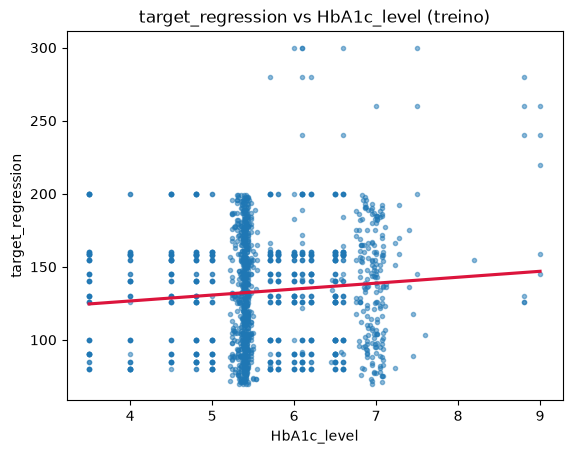

Só com HbA1c_level: declive = 4.06 | R2 = 0.0083


In [9]:
sns.regplot(x="HbA1c_level", y=target, data=train, order=1, ci=None,
            scatter_kws={"s": 9, "alpha": 0.5}, line_kws={"color": "crimson"})
plt.title("target_regression vs HbA1c_level (treino)")
plt.show()

simple = smf.ols(f"{target} ~ HbA1c_level", train).fit()
print(f"Só com HbA1c_level: declive = {simple.params['HbA1c_level']:.2f} | R2 = {simple.rsquared:.4f}")

**Leitura:** o teste F rejeita $H_0$ (p ≈ 0,020), mas o $R^2$ é muito baixo (0,031) e o $R^2$ ajustado ainda mais (0,011). Só quatro preditores têm p-value < 0,05: `HbA1c_level` (p ≈ 0,0005), `sleep_hours`, `high_ldl_cholesterol` e `bmi` (os três por pouco, entre 0,037 e 0,048). Com 31 testes esperam-se cerca de 1,6 resultados "significativos" só por acaso, por isso só `HbA1c_level` é claramente forte. Mesmo esse tem uma reta quase plana face à nuvem de pontos: o efeito existe (+4 no alvo por unidade de HbA1c), mas explica menos de 1% da variância.

---
## 6. Pergunta 2: todos os preditores ou só um subconjunto?

Comparam-se grupos de preditores, cada um ajustado no treino com `LinearRegression`:

- **Todos**: os 31 preditores `clean`;
- **Significativos**: os da pergunta 1 (p < 0,05);
- **Top-k**: os $k$ preditores com maior $|r|$ com o alvo no treino ($k$ = 1, 3, 5, 10);
- **Baseline**: prever sempre a média do treino.

**Como escolher sem usar o teste?** Com validação cruzada de 5 partes dentro do treino: escolhe-se o grupo com menor RMSE médio nas 5 partes. O teste só serve para avaliar o grupo escolhido, com $R^2$, MAE e RMSE.

In [10]:
def rmse(y_true, y_pred):
    return mean_squared_error(y_true, y_pred) ** 0.5

ranked = train[clean].corrwith(y_train).abs().sort_values(ascending=False).index.tolist()
groups = {
    "Todos": clean,
    "Significativos": significant,
    "Top-1": ranked[:1],
    "Top-3": ranked[:3],
    "Top-5": ranked[:5],
    "Top-10": ranked[:10],
}
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluate(model, cols):
    model.fit(train[cols], y_train)
    pred_test = model.predict(test[cols])
    cv_rmse = -cross_val_score(model, train[cols], y_train, cv=cv, scoring="neg_root_mean_squared_error").mean()
    return {
        "nº preditores": len(cols),
        "RMSE validação cruzada": cv_rmse,
        "R2 treino": r2_score(y_train, model.predict(train[cols])),
        "R2 teste": r2_score(y_test, pred_test),
        "MAE teste": mean_absolute_error(y_test, pred_test),
        "RMSE teste": rmse(y_test, pred_test),
    }

results = pd.DataFrame({name: evaluate(skl_lm.LinearRegression(), cols) for name, cols in groups.items()}).T
results.loc["Baseline (média do treino)"] = evaluate(DummyRegressor(strategy="mean"), ["age"])
results["nº preditores"] = results["nº preditores"].astype(int)
results.loc["Baseline (média do treino)", "nº preditores"] = 0
display(results.round(4))

candidates = results.drop("Baseline (média do treino)")
best_name = candidates["RMSE validação cruzada"].idxmin()
best_cols = groups[best_name]
print(f"Grupo escolhido (menor RMSE na validação cruzada): {best_name} -> {best_cols}")

,nº preditores,RMSE validação cruzada,R2 treino,R2 teste,MAE teste,RMSE teste
Todos,31,38.8030,0.0306,0.0063,32.3367,38.9421
Significativos,4,38.4397,0.0150,0.0202,32.0733,38.6687
Top-1,1,38.4810,0.0083,0.0209,31.8686,38.6552
Top-3,3,38.4196,0.0147,0.0180,32.0442,38.7135
Top-5,5,38.4298,0.0177,0.0185,32.0193,38.7024
Top-10,10,38.4333,0.0231,0.0210,32.1045,38.6540
Baseline (média do treino),0,38.6261,0.0000,-0.0068,32.2355,39.1987


Grupo escolhido (menor RMSE na validação cruzada): Top-3 -> ['HbA1c_level', 'employment_status_Retired', 'sleep_hours']


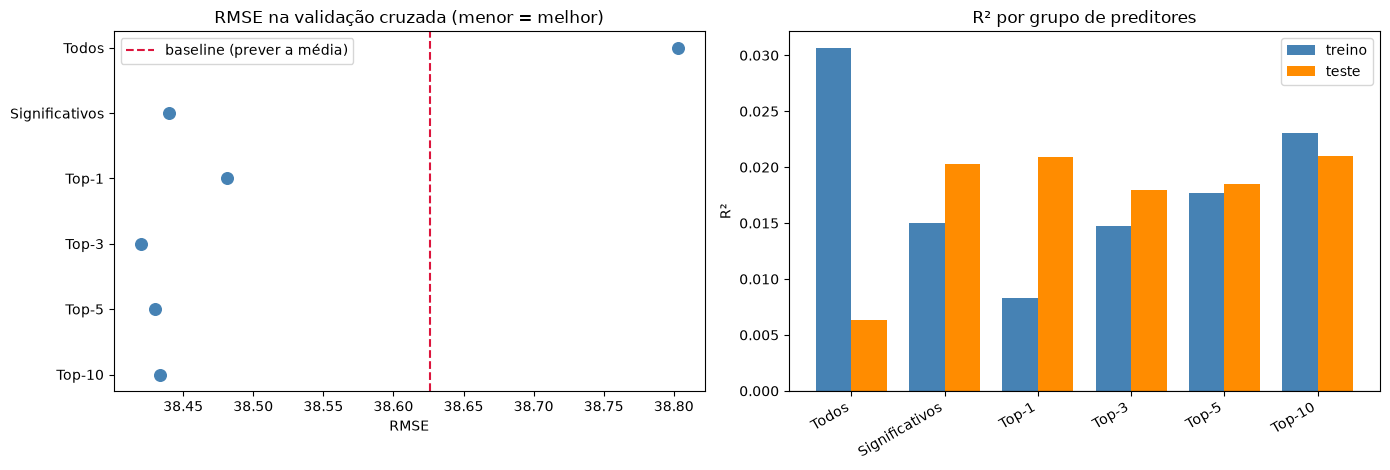

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
plot = results.drop("Baseline (média do treino)")

axes[0].scatter(plot["RMSE validação cruzada"], plot.index, s=70, color="steelblue", zorder=2)
axes[0].axvline(results.loc["Baseline (média do treino)", "RMSE validação cruzada"], color="crimson", ls="--",
                label="baseline (prever a média)")
axes[0].invert_yaxis()
axes[0].set(title="RMSE na validação cruzada (menor = melhor)", xlabel="RMSE")
axes[0].legend()

x = np.arange(len(plot))
axes[1].bar(x - 0.19, plot["R2 treino"], 0.38, label="treino", color="steelblue")
axes[1].bar(x + 0.19, plot["R2 teste"], 0.38, label="teste", color="darkorange")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(plot.index, rotation=30, ha="right")
axes[1].set(title="R² por grupo de preditores", ylabel="R²")
axes[1].legend()

plt.tight_layout()
plt.show()

**Leitura:**
- **Todos os preditores é o pior grupo:** tem o $R^2$ de treino mais alto (0,031) mas o de teste mais baixo (0,006) e o pior RMSE na validação cruzada (38,80, pior do que os 38,63 da baseline). Os preditores a mais ajustam ruído (sobreajuste).
- **Os grupos pequenos são equivalentes:** o RMSE na validação cruzada fica entre 38,42 e 38,48, e todos batem a baseline. O menor é o do `Top-3`, e é esse o grupo escolhido, por a regra não usar o teste. No teste, os grupos pequenos ficam todos entre 38,65 e 38,71 de RMSE, pelo que a ordem entre eles é ruído.
- **Porque não escolher pelo teste?** Escolher o melhor no teste e depois reportar esse mesmo valor seria otimista. Assim, o resultado do grupo escolhido no teste é uma estimativa honesta.
- **Limitação:** os grupos `Significativos` e `Top-k` foram escolhidos com todo o treino, por isso o seu RMSE de validação cruzada é ligeiramente otimista face ao de `Todos`. O teste não foi usado em nenhuma escolha.

### Seleção *forward*: uma pesquisa mais sistemática

Os grupos acima são só 6 das combinações possíveis, e testar todas é inviável ($2^{31} \approx 2{,}1 \times 10^9$). Usa-se por isso a seleção *forward*: começa-se sem preditores e, em cada passo, entra o que mais baixa o RMSE na validação cruzada (as mesmas 5 partes do treino). Ajustam-se $31 + 30 + \dots + 1 = 496$ modelos. O teste continua sem ser usado para escolher.

Mínimo com 12 preditores (RMSE na validação cruzada = 38.3568)


,entra,RMSE validação cruzada
nº preditores,,
1,HbA1c_level,38.4810
2,employment_status_Employed,38.4447
3,sleep_hours,38.4214
4,systolic_bp,38.4092
5,gender,38.3980
6,stress_level,38.3849
7,high_ldl_cholesterol,38.3746
8,education_level_Tertiary,38.3666
9,diastolic_bp,38.3649


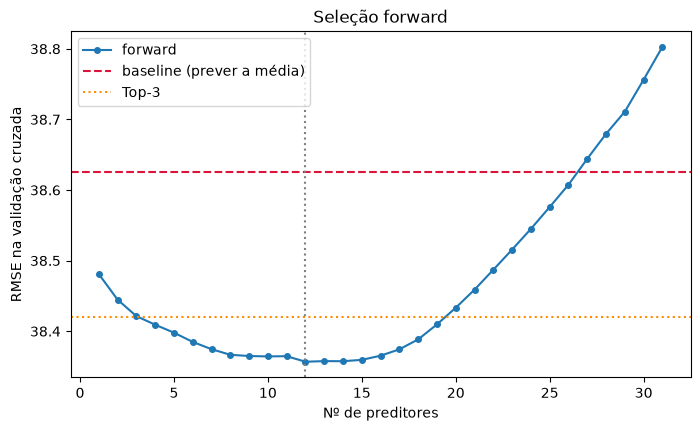

,nº preditores,RMSE validação cruzada,R2 treino,R2 teste,MAE teste,RMSE teste
Top-3 (escolhido),3,38.4196,0.0147,0.0180,32.0442,38.7135
Forward (k = 12),12,38.3568,0.0246,0.0215,31.9900,38.6436


In [12]:
selected, remaining, steps = [], list(clean), []
while remaining:
    scores = {col: -cross_val_score(skl_lm.LinearRegression(), train[selected + [col]], y_train,
                                    cv=cv, scoring="neg_root_mean_squared_error").mean()
              for col in remaining}
    entry = min(scores, key=scores.get)
    selected.append(entry)
    remaining.remove(entry)
    steps.append({"nº preditores": len(selected), "entra": entry, "RMSE validação cruzada": scores[entry]})
steps = pd.DataFrame(steps).set_index("nº preditores")

k_best = int(steps["RMSE validação cruzada"].idxmin())
forward_cols = selected[:k_best]
print(f"Mínimo com {k_best} preditores (RMSE na validação cruzada = {steps['RMSE validação cruzada'].min():.4f})")
display(steps.head(k_best).round(4))

plt.figure(figsize=(8, 4.5))
plt.plot(steps.index, steps["RMSE validação cruzada"], marker="o", ms=4, label="forward")
plt.axhline(results.loc["Baseline (média do treino)", "RMSE validação cruzada"], color="crimson", ls="--",
            label="baseline (prever a média)")
plt.axhline(results.loc["Top-3", "RMSE validação cruzada"], color="darkorange", ls=":", label="Top-3")
plt.axvline(k_best, color="gray", ls=":")
plt.xlabel("Nº de preditores")
plt.ylabel("RMSE na validação cruzada")
plt.title("Seleção forward")
plt.legend()
plt.show()

compare_fw = pd.DataFrame({
    "Top-3 (escolhido)": evaluate(skl_lm.LinearRegression(), best_cols),
    f"Forward (k = {k_best})": evaluate(skl_lm.LinearRegression(), forward_cols),
}).T
compare_fw["nº preditores"] = compare_fw["nº preditores"].astype(int)
display(compare_fw.round(4))

**Leitura:**
- Os primeiros preditores a entrar são `HbA1c_level`, `employment_status_Employed` e `sleep_hours`, quase os mesmos do `Top-3` (muda só a categoria de `employment_status` que entra: *Employed* em vez de *Retired*).
- A curva é quase plana: o RMSE na validação cruzada passa de 38,48 com 1 preditor para 38,36 no mínimo (12 preditores) e volta a subir com os 31 (38,80). A diferença entre 3 e 12 preditores (≈ 0,06) é muito menor do que a variação entre partes da validação cruzada (desvio-padrão ≈ 1,3).
- No teste, o modelo com 12 preditores é equivalente ao `Top-3` ($R^2$ de 0,022 contra 0,018; RMSE de 38,64 contra 38,71).
- Mantém-se o `Top-3`: o ganho está dentro do ruído, usa menos preditores e o RMSE de validação cruzada do *forward* é otimista, porque os mesmos dados serviram para escolher os preditores e para os avaliar.

---
## 7. Pergunta 3: quão bem se ajusta o modelo?

$R^2$ é a proporção da variância explicada: $R^2 = \dfrac{TSS - RSS}{TSS} = 1 - \dfrac{RSS}{TSS}$, com $RSS = \sum(y_i - \hat y_i)^2$ e $TSS = \sum(y_i - \bar y)^2$. Avalia-se o grupo escolhido no treino e no teste, e compara-se com a baseline (prever a média).

In [13]:
final = skl_lm.LinearRegression().fit(train[best_cols], y_train)
pred_train, pred_test = final.predict(train[best_cols]), final.predict(test[best_cols])
pred_base = np.full(len(test), y_train.mean())

rss = ((y_train - pred_train) ** 2).sum()
tss = ((y_train - y_train.mean()) ** 2).sum()
print(f"Treino: RSS = {rss:,.0f} | TSS = {tss:,.0f} | 1 - RSS/TSS = {1 - rss / tss:.4f} (r2_score: {r2_score(y_train, pred_train):.4f})")

metrics = pd.DataFrame({
    "R2": [r2_score(y_train, pred_train), r2_score(y_test, pred_test), r2_score(y_test, pred_base)],
    "MAE": [mean_absolute_error(y_train, pred_train), mean_absolute_error(y_test, pred_test), mean_absolute_error(y_test, pred_base)],
    "RMSE": [rmse(y_train, pred_train), rmse(y_test, pred_test), rmse(y_test, pred_base)],
}, index=["modelo (treino)", "modelo (teste)", "baseline (teste)"])
display(metrics.round(4))

Treino: RSS = 2,351,917 | TSS = 2,387,113 | 1 - RSS/TSS = 0.0147 (r2_score: 0.0147)


,R2,MAE,RMSE
modelo (treino),0.0147,31.8082,38.3399
modelo (teste),0.0180,32.0442,38.7135
baseline (teste),-0.0068,32.2355,39.1987


In [14]:
est_final = smf.ols(f"{target} ~ " + " + ".join(best_cols), train).fit()
print(f"F = {est_final.fvalue:.2f} (p = {est_final.f_pvalue:.5f}) | R2 ajustado = {est_final.rsquared_adj:.4f}")
display(est_final.summary().tables[1])

same_coef = np.allclose(est_final.params.drop("Intercept"), final.coef_) and np.isclose(est_final.params["Intercept"], final.intercept_)
print("statsmodels e scikit-learn dão os mesmos coeficientes:", same_coef)

F = 7.96 (p = 0.00003) | R2 ajustado = 0.0129


,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,101.4070,8.087,12.540,0.000,85.545,117.269
HbA1c_level,4.0756,1.106,3.684,0.000,1.906,6.245
employment_status_Retired,-4.7621,2.020,-2.357,0.019,-8.725,-0.799
sleep_hours,1.5227,0.712,2.139,0.033,0.126,2.919


statsmodels e scikit-learn dão os mesmos coeficientes: True


**Leitura:**
- O modelo explica ≈ 1,5% da variância no treino e ≈ 1,8% no teste. O teste F é significativo (p < 0,001) e os três coeficientes têm p < 0,05: há relação, mas muito pequena.
- Teste ligeiramente acima do treino não indica sobreajuste: com um ajuste tão fraco, a diferença é variação da partição.
- No teste, o RMSE (38,71) e o MAE (32,04) ficam pouco abaixo dos da baseline (39,20 e 32,24). O ganho é pequeno.
- Os coeficientes lêem-se "com os outros fixos": +1 unidade de `HbA1c_level` soma ≈ 4,08 ao alvo, +1 hora de `sleep_hours` soma ≈ 1,52, e ser reformado (`employment_status_Retired`) desce ≈ 4,76 face ao grupo de referência (`Unemployed`).
- `statsmodels` e `scikit-learn` dão os mesmos coeficientes, como no slide de verificação cruzada.

---
## 8. Pergunta 4: previsões

Dados os valores dos preditores, o modelo devolve $\hat y = \hat\beta_0 + \hat\beta_1 x_1 + \dots + \hat\beta_p x_p$ (`model.predict`). Mostram-se previsões para observações do teste, que o modelo não viu no treino.

In [15]:
sample = pd.DataFrame({"real": y_test.values[:8], "previsto": pred_test[:8]})
sample["erro"] = sample["real"] - sample["previsto"]
display(sample.round(1))

print(f"MAE = {mean_absolute_error(y_test, pred_test):.2f} | RMSE = {rmse(y_test, pred_test):.2f} "
      f"| desvio-padrão de {target} no teste = {y_test.std():.2f}")

,real,previsto,erro
0,160.0,137.1,22.9
1,126.0,135.8,-9.8
2,280.0,137.8,142.2
3,152.0,132.1,19.9
4,80.0,136.5,-56.5
5,80.0,127.5,-47.5
6,85.0,137.3,-52.3
7,158.0,132.5,25.5


MAE = 32.04 | RMSE = 38.71 | desvio-padrão de target_regression no teste = 39.12


**Leitura:** nestas observações os valores previstos ficam todos entre ≈ 128 e 138, enquanto os reais vão de 80 a 280. O erro típico (MAE ≈ 32, RMSE ≈ 39) é do tamanho do desvio-padrão do próprio alvo (≈ 39): o modelo prevê pouco melhor do que a média.

---
## 9. Problemas potenciais do modelo

Os slides listam vários problemas possíveis, entre eles a não linearidade da relação e a variância não constante dos erros. A colinearidade entre preditores já foi tratada na secção 3. Para os outros dois usa-se o gráfico dos resíduos face aos valores ajustados, e compara-se o previsto com o real no teste.

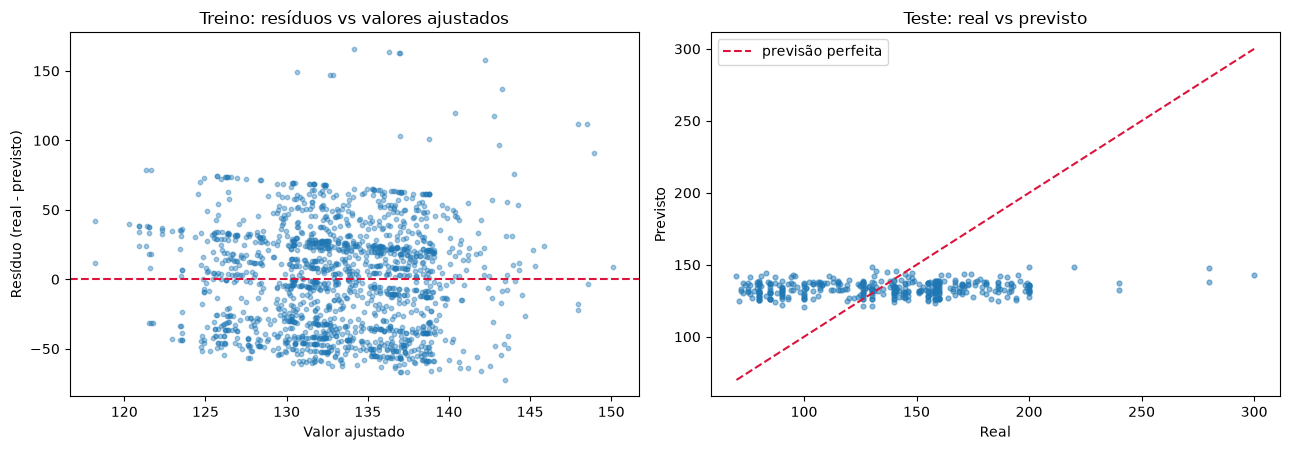

Desvio-padrão dos resíduos por terço dos valores ajustados (do mais baixo ao mais alto):
1.º terço    36.18
2.º terço    37.40
3.º terço    41.39


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

axes[0].scatter(pred_train, y_train - pred_train, s=10, alpha=0.4)
axes[0].axhline(0, color="crimson", ls="--")
axes[0].set(title="Treino: resíduos vs valores ajustados", xlabel="Valor ajustado", ylabel="Resíduo (real - previsto)")

axes[1].scatter(y_test, pred_test, s=12, alpha=0.5)
lims = [y_test.min(), y_test.max()]
axes[1].plot(lims, lims, color="crimson", ls="--", label="previsão perfeita")
axes[1].set(title="Teste: real vs previsto", xlabel="Real", ylabel="Previsto")
axes[1].legend()

plt.tight_layout()
plt.show()

resid_train = y_train - pred_train
spread = resid_train.groupby(pd.qcut(pred_train, 3, labels=["1.º terço", "2.º terço", "3.º terço"]), observed=True).std()
print("Desvio-padrão dos resíduos por terço dos valores ajustados (do mais baixo ao mais alto):")
print(spread.round(2).to_string())

**Leitura:**
- Os valores ajustados ocupam uma faixa estreita (≈ 118 a 150), enquanto os reais vão de 70 a 300: o modelo explica pouco. Os resíduos reproduzem a dispersão do próprio alvo.
- Não se vê curvatura nos resíduos, pelo que este gráfico não mostra não linearidade. A dispersão dos resíduos sobe um pouco nos valores ajustados mais altos (36 para 41), o que é pouco para concluir variância não constante.
- Há valores reais muito acima do previsto (até 300) que o modelo não capta.

---
## 10. Comparação: regressão simples vs múltipla

O enunciado pede para comparar o modelo com uma só variável e o modelo com várias, com $R^2$, MAE e RMSE. O modelo simples usa o preditor com maior $|r|$ com o alvo no treino (o `Top-1` da secção 6). Ajusta-se no mesmo treino e avalia-se no mesmo teste que o modelo múltiplo escolhido, para os números serem comparáveis.

In [17]:
simple_col = ranked[0]
simple_model = skl_lm.LinearRegression().fit(train[[simple_col]], y_train)
pred_simple = simple_model.predict(test[[simple_col]])
print(f"Simples: {target} = {simple_model.intercept_:.2f} + {simple_model.coef_[0]:.2f} * {simple_col}")

models = {
    f"Simples ({simple_col})": pred_simple,
    f"Múltipla ({best_name}, {len(best_cols)} preditores)": pred_test,
    "Baseline (média do treino)": pred_base,
}
comparison = pd.DataFrame({
    name: {"R2": r2_score(y_test, p), "MAE": mean_absolute_error(y_test, p), "RMSE": rmse(y_test, p)}
    for name, p in models.items()
}).T
display(comparison.round(4))

Simples: target_regression = 110.37 + 4.06 * HbA1c_level


,R2,MAE,RMSE
Simples (HbA1c_level),0.0209,31.8686,38.6552
"Múltipla (Top-3, 3 preditores)",0.0180,32.0442,38.7135
Baseline (média do treino),-0.0068,32.2355,39.1987


**Leitura:**
- No teste, o modelo simples e o múltiplo ficam praticamente iguais nos três indicadores (a diferença de RMSE é de 0,06) e ambos melhoram ligeiramente a baseline.
- Acrescentar `employment_status_Retired` e `sleep_hours` a `HbA1c_level` não melhorou o teste ($R^2$ de 0,018 contra 0,021). Na validação cruzada o múltiplo é um pouco melhor (RMSE 38,42 contra 38,48), mas a ordem inverte-se no teste: a diferença entre os dois é ruído da partição.
- Quase toda a informação útil está em `HbA1c_level`. Com $R^2$ ≈ 0,02, nenhum dos modelos prevê bem `target_regression`.

---
## 11. Conclusões

- **Preditores úteis:** só `HbA1c_level` (p ≈ 0,0005), `sleep_hours`, `high_ldl_cholesterol` e `bmi` têm p-value < 0,05 no modelo completo, com efeitos pequenos. Com 31 testes, parte disto pode ser acaso.
- **Todos ou subconjunto:** usar todos os preditores é pior (sobreajuste). Com validação cruzada no treino, o grupo escolhido foi `Top-3`: `HbA1c_level`, `employment_status_Retired` e `sleep_hours`.
- **Seleção forward:** a pesquisa passo a passo põe à cabeça os mesmos preditores; o mínimo (12 preditores) é equivalente ao `Top-3` dentro do ruído, que se mantém por ser mais simples.
- **Ajuste:** $R^2$ ≈ 0,015 no treino e ≈ 0,018 no teste; MAE ≈ 32,0 e RMSE ≈ 38,7 no teste, contra 32,2 e 39,2 de prever sempre a média.
- **Simples vs múltipla:** no teste, `HbA1c_level` sozinha e o grupo `Top-3` têm desempenho equivalente (RMSE ≈ 38,7 nos dois, contra 39,2 da baseline).
- **Previsões:** ficam perto da média; o erro é do tamanho do desvio-padrão do alvo.
- **Conclusão geral:** a regressão linear múltipla explica muito pouco de `target_regression`. Os slides indicam a não linearidade como causa possível; testar termos polinomiais fica fora do âmbito deste notebook.